In [2]:
import math
import numpy as np
import matplotlib.pyplot as plt
import random

In [1172]:
class Value:
    def __init__(self, value, _children = (), _op = '', label = ''):
        self.value = value
        self._prev = set(_children)
        self._op = _op
        self.label = label
        self.grad = 0
        self._backward = lambda: None
        self._topo = []

    def __repr__(self):
        return (f'Value(data={self.value})')

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other, label=str(other))
        out = Value(value = self.value + other.value, _children = (self, other), _op = '+', label = '')

        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad
        
        out._backward = _backward
        
        return out

    def __radd__(self, other):
        return self + other

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other, label=str(other))
        out = Value(value = self.value * other.value, _children = (self, other), _op = '*', label = '')
        
        def _backward():
            self.grad += other.value * out.grad
            other.grad += self.value * out.grad
        
        out._backward = _backward
        
        return out

    def __rmul__(self, other):
        return self * other

    def __truediv__(self, other):
        return self * other ** -1

    def __neg__(self):
        return self * -1

    def __sub__(self, other):
        return self + (-other)

    def __pow__(self, other):
        assert isinstance(other, (int, float)), 'only supporting int/float powers for now'
        out = Value(self.value ** other, (self, ), f'**{other}')

        def _backward():
            self.grad += out.grad * other * (self.value ** (other - 1))

        out._backward = _backward

        return out

    def exp(self):
        x = self.value
        out = Value(value = math.exp(x), _children = (self, ), _op = 'exp', label = '')

        def _backward():
            self.grad += out.grad * out.value

        out._backward = _backward

        return out

    def tanh(self):
        v = self.value
        e2x = np.exp(2*v)
        t = (e2x - 1) / (e2x + 1)
        out = Value(value = t, _children=(self,), _op = 'tanh', label=f'')

        def _backward():
            self.grad += (1 - t ** 2) * out.grad
        
        out._backward = _backward

        return out

    def _build_topo(self):
        topo = []
        visited = set()

        def build_topo(v):
                    if v not in visited:
                        visited.add(v)
                        for child in v._prev:
                            build_topo(child)
                        topo.append(v)
        
        build_topo(self)
        self._topo = topo

    def backward(self):
        if not self._topo:
            self._build_topo()
        
        self.grad = 1

        for node in reversed(self._topo):
            node._backward()


    def grad_zero(self):
        if not self._topo:
            self._build_topo()

        for node in reversed(self._topo):
            node._grad = 0

        self.grad = 1

In [3]:
a = Value(2, label='a')
b = Value(-3, label='b')
c = Value(10, label='c')
f = Value(-2, label = 'f')

In [4]:
b-a

Value(b+a*-1, data=-5)

In [5]:
e = a * b; e.label = 'e'
d = c + e; d.label = 'd'
L = d * f; L.label = 'L'

In [4]:
from graphviz import Digraph

def trace(root):
  # builds a set of all nodes and edges in a graph
  nodes, edges = set(), set()
  def build(v):
    if v not in nodes:
      nodes.add(v)
      for child in v._prev:
        edges.add((child, v))
        build(child)
  build(root)
  return nodes, edges

def draw_dot(root):
  dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = left to right
  
  nodes, edges = trace(root)
  for n in nodes:
    uid = str(id(n))
    # for any value in the graph, create a rectangular ('record') node for it
    dot.node(name = uid, label = "{ %s | data %.4f | grad %.4f }" % (n.label, n.value, n.grad), shape='record')
    if n._op:
      # if this value is a result of some operation, create an op node for it
      dot.node(name = uid + n._op, label = n._op)
      # and connect this node to it
      dot.edge(uid + n._op, uid)

  for n1, n2 in edges:
    # connect n1 to the op node of n2
    dot.edge(str(id(n1)), str(id(n2)) + n2._op)

  return dot


### Neuron example

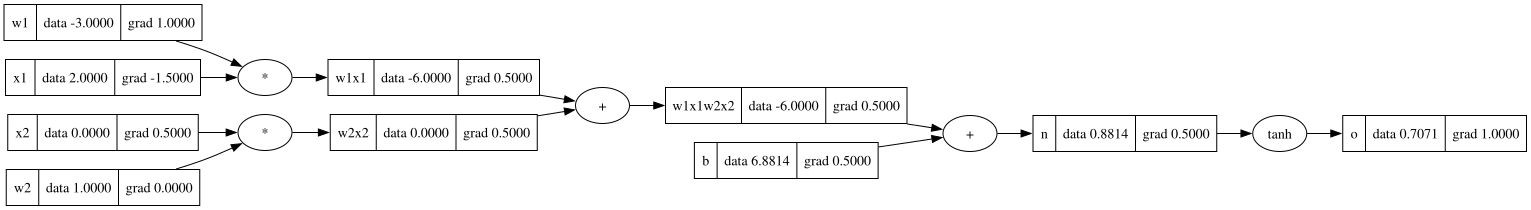

In [5]:
x1 = Value(2., label='x1')
x2 = Value(0., label='x2')

w1 = Value(-3., label='w1')
w2 = Value(1., label='w2')

b = Value(6.8813735870195432, label='b')

w1x1 = w1*x1; w1x1.label = 'w1x1'
w2x2 = w2*x2; w2x2.label = 'w2x2'

w1x1w2x2 = w1x1 + w2x2; w1x1w2x2.label = 'w1x1w2x2'
n = w1x1w2x2 + b; n.label = 'n'
o = n.tanh(); o.label = 'o'
o.backward()
draw_dot(o)

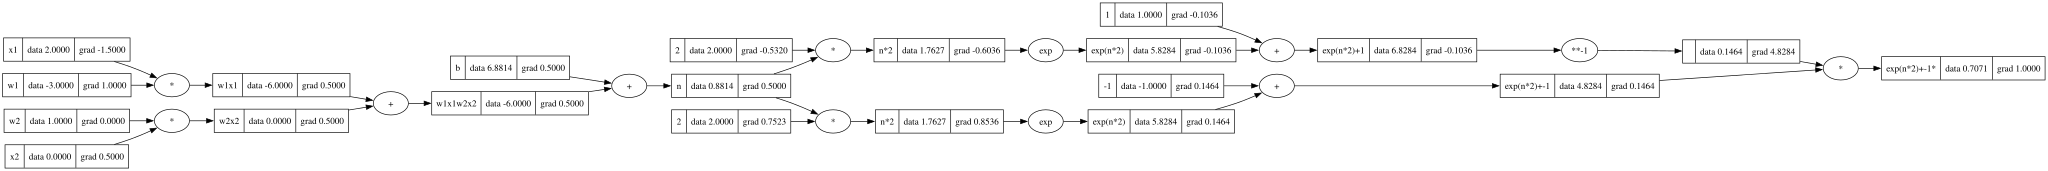

In [6]:
x1 = Value(2., label='x1')
x2 = Value(0., label='x2')

w1 = Value(-3., label='w1')
w2 = Value(1., label='w2')

b = Value(6.8813735870195432, label='b')

w1x1 = w1*x1; w1x1.label = 'w1x1'
w2x2 = w2*x2; w2x2.label = 'w2x2'

w1x1w2x2 = w1x1 + w2x2; w1x1w2x2.label = 'w1x1w2x2'
n = w1x1w2x2 + b; n.label = 'n'
o = ((2*n).exp() - 1)/((2*n).exp() + 1)
# o = n.tanh()
o.backward()
draw_dot(o)

### PyTorch

In [7]:
import torch
import torch.nn as nn
import torch.functional as F

In [8]:
x1 = torch.tensor([2.], requires_grad=True).double()
x2 = torch.tensor([0.], requires_grad=True).double()
w1 = torch.tensor([-3.], requires_grad=True).double()
w2 = torch.tensor([1.], requires_grad=True).double()
b = torch.tensor([6.8813735870195432], requires_grad=True).double()
n = w1*x1 + w2*x2 + b
o = torch.tanh(n)

o.backward()

In [9]:
b.retain_grad()

### Neuron & Layer Classes

In [1173]:
class Neuron:

    def __init__(self, n_in):
        self.w = [Value(random.uniform(-1,1)) for _ in range(n_in)]
        self.b = Value(random.uniform(-1,1))

    def __call__(self, x):
        assert len(self.w) == len(x), "Input vector and weight vector must have same dims!"
        act = sum((w_i*x_i for w_i, x_i in zip(self.w, x)),self.b)
        out = act.tanh()
        return out

    def parameters(self):
        return self.w + [self.b]

class Layer:

    def __init__(self, n_in, n_out):
        self.neurons = [Neuron(n_in) for _ in range(n_out)]

    def __call__(self, x):
        outs = [neuron(x) for neuron in self.neurons]
        return outs

    def parameters(self):
        return [p for neuron in self.neurons for p in neuron.parameters()]

In [156]:
n_in, n_out = 5, 15
a = Layer(n_in, n_out)

In [157]:
input = [random.uniform(0, 100) for _ in range(n_in)]

In [158]:
a(input)

[Value(data=1.0),
 Value(data=1.0),
 Value(data=-1.0),
 Value(data=-1.0),
 Value(data=1.0),
 Value(data=-0.9999982267380189),
 Value(data=1.0),
 Value(data=-1.0),
 Value(data=-1.0),
 Value(data=1.0),
 Value(data=-1.0),
 Value(data=1.0),
 Value(data=-1.0),
 Value(data=1.0),
 Value(data=-1.0)]

In [1103]:
class MLP:

    def __init__(self, n_in, n_outs):
        sz = [n_in] + n_outs
        self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(n_outs))]
        self.sz = sz

    def __call__(self, x):
        for l in self.layers:
            x = l(x)

        return x[0] if len(x) == 1 else x

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]

In [1104]:
a = MLP(3, [4,4,1])

In [1105]:
input = [random.uniform(-100,100) for _ in range(3)]
a(input)

Value(data=-0.8305380797802967)

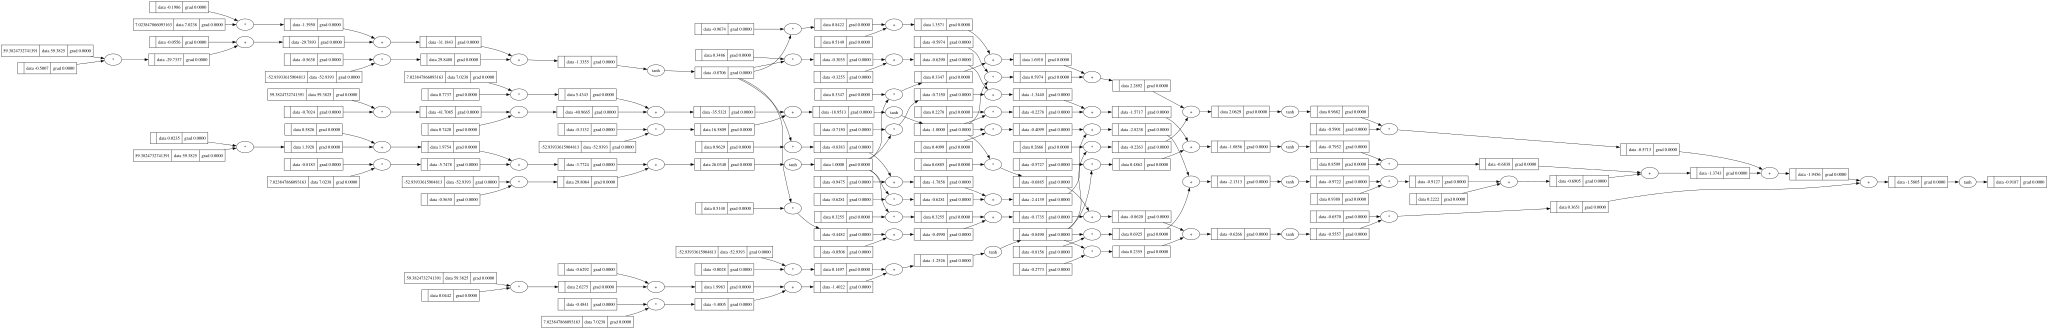

In [909]:
draw_dot(a(input))

### Example Binary Classification Dataset

In [975]:
xs = [
    [2., 3., -1.],
    [3., -1., .5],
    [.5, 1., 1.],
    [1., 1., -1.]
    ]

ys = [1, -1., -1., 1]

y_pred = [a(row) for row in xs]
y_pred

[Value(data=-0.2777810878029852),
 Value(data=-0.5167631728557951),
 Value(data=-0.5839382421454062),
 Value(data=-0.47206665653693664)]

In [976]:
loss = [(yp - yt)**2 for yt, yp in zip(ys, y_pred)]
loss

[Value(data=1.6327245083469801),
 Value(data=0.23351783110839816),
 Value(data=0.17310738634905462),
 Value(data=2.1669802412878356)]

In [977]:
cost = sum(loss)
print(cost)

Value(data=4.206329967092268)


In [978]:
# Computing gradients wrt cost function
cost.backward()

In [979]:
len(a.parameters())

41

In [980]:
a.layers[0].neurons[0].w[0].grad

np.float64(-0.12061440591794864)

In [1035]:
lr = 0.01

for p in a.parameters():
    p.value += -lr * p.grad

y_pred = [a(row) for row in xs]
loss = [(yp - yt)**2 for yt, yp in zip(ys, y_pred)]
cost = sum(loss)
cost.backward()
print(cost)

Value(data=1.0245629817080716e-08)


In [1036]:
y_pred

[Value(data=0.9999002992949321),
 Value(data=-0.9999999982643256),
 Value(data=-0.9999999982625978),
 Value(data=0.9999825243249055)]

In [966]:
cost.grad_zero()

### Proper Training Loop

In [1233]:
a = MLP(3, [20,15,1])

xs = [
    [2., 3., -1.],
    [3., -1., .5],
    [.5, 1., 1.],
    [1., 1., -1.]
    ]

ys = [1., -1., -1., 1.]

y_pred = [a(row) for row in xs]
loss = [(yp - yt)**2 for yt, yp in zip(ys, y_pred)]
cost = sum(loss)
cost.grad_zero()
cost.backward()

In [1234]:
epochs = 0
lr = 0.05

while cost.value > 1e-12 and epochs < 50000:
    for p in a.parameters():
        p.value -= lr * p.grad

    y_pred = [a(row) for row in xs]
    loss = [(yp - yt)**2 for yt, yp in zip(ys, y_pred)]
    cost = sum(loss)
    cost.backward()
    epochs += 1

    if epochs % 1000 == 0:
        print(f'Epoch: {epochs}\nCost: {cost.value}\nPredictions: {[round(v.value, 5) for v in y_pred]}')

print(f'Training done\n\nEpochs: {epochs}\nCost:{cost.value}\nPredictions:{y_pred}')

Training done

Epochs: 28
Cost:7.02126019229646e-13
Predictions:[Value(data=0.9999999999982556), Value(data=-0.9999999999735989), Value(data=-0.9999991620703976), Value(data=0.9999999999995108)]
